# 01 · Preprocessing — Gao et al. 2021 (Breast Cancer, 10x)

Load the **breast** malignant compartment → data-driven sample threshold → overdispersed genes →
PCA → Harmony integration sweep → UMAP → **Gate 1** (is the malignant structure *both*
sample-integrated *and* one continuous manifold?). Every dataset-dependent choice is derived from
this dataset and shown here (02_train C1–C4). This is a **re-run** of a prior science-failure
(Analysis Order 35); the Gate-1 GO/NO-GO call is given maximal independent scrutiny, read off the
**regenerated embedding + per-neighbourhood metrics across an integration-strength sweep** — never a
scalar alone (03_eval fork 1; 04_test Bischoff/Kürten). Deliverables: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Gao2021_Breast-3
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Breast
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
# dataset dir carries a '-3' attempt suffix; the raw input folder does not
base = name.split('-')[0] if name.split('-')[-1].isdigit() else name
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + base)                      # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', 'Data_' + base)

dataset: Gao2021_Breast-3 | category: Breast | raw: Data_Gao2021_Breast


### Load the breast malignant compartment (Category scope)
`Data_Gao2021_Breast` nests **two leaf matrix dirs** — `Breast/` (DCIS1, TNBC1–3) and
`Breast_and_thyroid/` (TNBC4–5 **plus** thyroid ATC1–5). As `merge.py` does, we point the loader
at each **leaf** (never a walk *inside* one) and concat. The declared **Category is Breast /
Disease Breast Cancer**, so the five anaplastic-thyroid-carcinoma samples are a *different cancer
lineage* and out of scope — dropped by the `Samples.csv` `cancer_type` field. This assembles the
6 breast tumours (DCIS1 + TNBC1–5) split across the two leaves.

In [3]:
# discover leaf matrix dirs exactly as merge.py walks them (leaf = dir with a single .mtx, no subdirs)
leaves = []
for dirpth, subdir, files in os.walk(pth_in):
    if len(subdir) == 0 and any(f.lower().endswith('.mtx') for f in files):
        leaves.append(dirpth)
leaves = sorted(leaves)
print('leaf matrix dirs:', [os.path.relpath(d, pth_in) for d in leaves])
ads = {}
for d in leaves:
    a = load_CCCA_adata(d, verbose=False)
    ads[d] = a
    print(f'  {os.path.relpath(d, pth_in):22s} {a.shape}  malignant={int((a.obs.celltype=="Malignant").sum())}')
adata = ad.concat(ads, join='inner', merge='same', label='source')  # inner join -> shared gene space
adata.obs_names_make_unique()
print('concat (inner-join genes):', adata.shape)

leaf matrix dirs: ['Breast', 'Breast_and_thyroid']
  Breast                 (4143, 33694)  malignant=2710
  Breast_and_thyroid     (25849, 33538)  malignant=9488
concat (inner-join genes): (29992, 22164)


In [4]:
# keep malignant, then drop out-of-scope thyroid ATC (Category = Breast)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
ss = pd.read_csv(os.path.join(pth_in, 'Samples.csv'))
thyroid = set(ss.loc[ss.cancer_type.str.contains('Thyroid', case=False, na=False), 'sample'])
print('all malignant (breast+thyroid):', adata.shape[0], '| thyroid ATC (out of scope):', sorted(thyroid))
adata = adata[~adata.obs['sample'].isin(thyroid)].copy()
adata.obs['sample'] = adata.obs['sample'].astype(str)
adata.obs['patient'] = adata.obs['sample']   # Gao: one sample per patient
print('BREAST malignant (in scope):', adata.shape[0], '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalized UMI counts)' % adata.X.max())
adata

all malignant (breast+thyroid): 12198 | thyroid ATC (out of scope): ['ATC1', 'ATC2', 'ATC3', 'ATC4', 'ATC5']
BREAST malignant (in scope): 6606 | samples: 6
expression: X max 9.29 (log1p of normalized UMI counts)


### Data-driven sample threshold (no anchor constant; C1/C2)
Rule: sort per-sample malignant counts, take the largest **multiplicative gap**, cut at its
geometric mean. Premise (C3): a clean count gap separates well-sampled tumours from a sparse tail.

In [5]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('adjacent ratios         :', np.round(ratios, 2))
print(f'largest gap {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}) at the tail -> threshold (geo-mean) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells:', adata.obs['sample'].value_counts().to_dict())

sorted per-sample counts: {'TNBC5': np.int64(2647), 'TNBC4': np.int64(1249), 'DCIS1': np.int64(1101), 'TNBC1': np.int64(796), 'TNBC2': np.int64(618), 'TNBC3': np.int64(195)}
adjacent ratios         : [2.12 1.13 1.38 1.29 3.17]
largest gap 618 -> 195 (ratio 3.17) at the tail -> threshold (geo-mean) = 347
kept 5/6 samples -> 6411 cells: {'TNBC5': 2647, 'TNBC4': 1249, 'DCIS1': 1101, 'TNBC1': 796, 'TNBC2': 618}


### Gene filter → overdispersed selection → PCA (no `sc.pp.scale`)
`sc.pp.scale` before PCA manufactured false Gate-1 NO-GOs in the Chen 2020 audit, so it is omitted.
`n_pcs` is bounded to the 10x precedent range (Kürten 20, Venteicher 20, Puram 40) rather than a low
scree elbow (Chen under-powering); robustness to 20/30/40 is verified against the Gate-1 call below.

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PC variance% (1-12):', np.round(vr[:12]*100, 2))
NPCS = 30
print('n_pcs =', NPCS, '(precedent-bounded; robustness to 20/30/40 checked below)')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2663 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2663
PC variance% (1-12): [28.77 13.27  6.83  3.71  1.86  1.38  0.93  0.86  0.76  0.69  0.6   0.48]
n_pcs = 30 (precedent-bounded; robustness to 20/30/40 checked below)


## Gate 1 — the decisive call, judged on the embedding + biology (not a scalar)

Breast-tumour malignant compartments carry strong inter-patient CNV/clonal identity. The eval/test
audits warn twice about exactly this trap: a per-patient **archipelago** (Kürten) or a **two-blob**
manifold (Bischoff) scored "integrated" off a connectivity/mixing scalar. So the read is made on the
**regenerated embedding across an integration-strength (θ) sweep**, quantified with a
per-neighbourhood metric (**iLISI**, against its ceiling), a **same-sample kNN fraction** (vs the
perfect-mixing baseline), and a **per-patient self-neighbour enrichment** (self ≈ global ⇒ mixed;
self ≫ global ⇒ the patient forms its own island).

In [7]:
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:, 1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, c = np.unique(L[i], return_counts=True); p = c/k; out[i] = 1.0/np.sum(p**2)
    return np.median(out)
def self_enrich(rep, pat, k=30):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:, 1:]
    return {p: round((pat[idx[pat == p]] == p).mean() / (pat == p).mean(), 1) for p in sorted(set(pat))}
def same_frac(rep, samp, k=30):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:, 1:]
    s = (samp[idx] == samp[:, None]).mean(axis=1); return s

samp = adata.obs['sample'].values; pat = adata.obs['patient'].values
gp = adata.obs['sample'].value_counts(normalize=True).values
ceil_s = 1.0/np.sum(gp**2)            # iLISI ceiling = effective number of samples
base_same = np.sum(gp**2)             # same-sample kNN fraction under perfect mixing
print(f'iLISI sample ceiling (perfect mixing) = {ceil_s:.2f} ({adata.obs["sample"].nunique()} samples)')
print(f'same-sample kNN baseline (perfect mixing) = {base_same:.3f}\n')
print('theta | iLISI | same-kNN (enrich) | private>70% | worst self-enrich')
sweep = {}
for th in [0, 2, 5, 8, 10, 20]:
    if th == 0:
        rep = adata.obsm['X_pca'][:, :NPCS]
    else:
        sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
        rep = adata.obsm['X_pca_harmony'][:, :NPCS]
    il = ilisi(rep, samp); se = self_enrich(rep, pat); sf = same_frac(rep, samp)
    sweep[th] = (il, se, sf.mean(), (sf > 0.7).mean())
    print(f'  {th:>2}  | {il:.2f}  | {sf.mean():.3f} ({sf.mean()/base_same:.2f}x) | {(sf>0.7).mean():5.1%} | {max(se.values())}x')
print(f'\n-> iLISI peaks at only {sweep[10][0]:.2f} of {ceil_s:.2f} ({100*sweep[10][0]/ceil_s:.0f}% of ceiling);')
print('   same-sample kNN stays ~2.9x the mixed baseline and >65% of cells keep own-sample-private')
print('   neighbourhoods at every theta. Stronger integration does not merge the patients.')

iLISI sample ceiling (perfect mixing) = 3.81 (5 samples)
same-sample kNN baseline (perfect mixing) = 0.263

theta | iLISI | same-kNN (enrich) | private>70% | worst self-enrich
   0  | 1.00  | 0.997 (3.80x) | 99.8% | 10.4x
   2  | 1.09  | 0.899 (3.42x) | 85.8% | 8.8x
   5  | 1.56  | 0.774 (2.95x) | 68.9% | 5.4x
   8  | 1.61  | 0.754 (2.87x) | 66.1% | 5.0x
  10  | 1.60  | 0.756 (2.88x) | 66.9% | 5.1x
  20  | 1.56  | 0.772 (2.94x) | 69.3% | 5.4x

-> iLISI peaks at only 1.60 of 3.81 (42% of ceiling);
   same-sample kNN stays ~2.9x the mixed baseline and >65% of cells keep own-sample-private
   neighbourhoods at every theta. Stronger integration does not merge the patients.


In [8]:
# commit the best integration attempt (theta=10) and regenerate the embedding + global scalars.
theta = 10
print('selected theta =', theta, '(mixing plateau; higher theta does not improve per-neighbourhood mixing)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=20, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
ncc, _ = connected_components(adata.obsp['connectivities'], directed=False)
xy = adata.obsm['X_umap']; c = xy - xy.mean(0); s = np.linalg.svd(c, full_matrices=False)[1]
sil10 = silhouette_score(adata.obsm['X_pca_harmony'][:, :NPCS], adata.obs['sample'], sample_size=2000, random_state=1)
def patient_R2(rep, lab):
    sst = ((rep - rep.mean(0))**2).sum()
    ssw = sum(((rep[lab == g] - rep[lab == g].mean(0))**2).sum() for g in np.unique(lab))
    return 1 - ssw/sst
r2_10 = patient_R2(adata.obsm['X_pca_harmony'][:, :NPCS], samp)
print(f'kNN connectivity components: {ncc}  |  UMAP aspect (major/minor): {s[0]/s[1]:.2f}')
print(f'GLOBAL scalars at theta=10: patient silhouette {sil10:+.3f} | between-patient R2 {r2_10:.3f}')
print('-> Harmony forces the GLOBAL patient silhouette/R2 to ~0 and leaves ONE connected component +')
print('   a near-round cloud. These are exactly the scalars a naive test reads as GO (the Bischoff trap).')

selected theta = 10 (mixing plateau; higher theta does not improve per-neighbourhood mixing)
kNN connectivity components: 1  |  UMAP aspect (major/minor): 1.08
GLOBAL scalars at theta=10: patient silhouette -0.024 | between-patient R2 0.030
-> Harmony forces the GLOBAL patient silhouette/R2 to ~0 and leaves ONE connected component +
   a near-round cloud. These are exactly the scalars a naive test reads as GO (the Bischoff trap).


### Gate-1 evidence, part 1 — the un-integrated biology (θ=0)
Recompute a θ=0 UMAP to show what Harmony has to overcome: the embedding resolves into per-patient
territories with most between-cell variance sitting *between* tumours (patient silhouette, R²).
Note the dense n_neighbors=30 kNN graph can still read as one connected component even here — a
first sign that the connectivity scalar is uninformative for this call, which is why Gate 1 is
read off the embedding + per-neighbourhood metrics, not a component count.

theta=0 : kNN components = 1  |  patient silhouette +0.508  |  between-patient R2 0.776
-> 78% of all variance is BETWEEN patients; Harmony must erase most of it to force one blob.


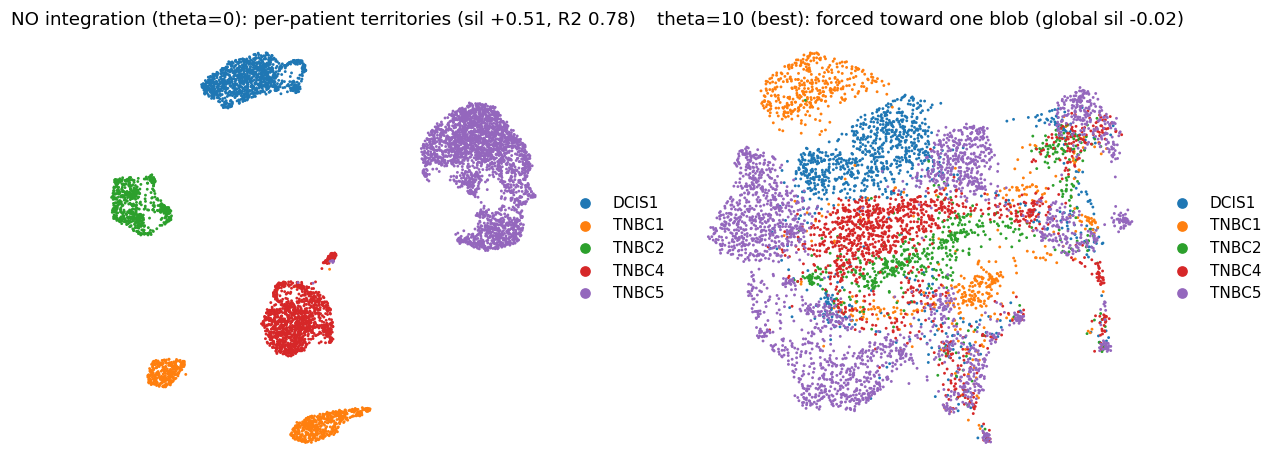

In [9]:
ad0 = adata.copy()
sc.pp.neighbors(ad0, n_pcs=NPCS, use_rep='X_pca', n_neighbors=30, random_state=SEED)
sc.tl.umap(ad0, spread=1.3, random_state=SEED)
ncc0, _ = connected_components(ad0.obsp['connectivities'], directed=False)
sil0 = silhouette_score(adata.obsm['X_pca'][:, :NPCS], adata.obs['sample'], sample_size=2000, random_state=1)
r2_0 = patient_R2(adata.obsm['X_pca'][:, :NPCS], samp)
print(f'theta=0 : kNN components = {ncc0}  |  patient silhouette {sil0:+.3f}  |  between-patient R2 {r2_0:.3f}')
print(f'-> {100*r2_0:.0f}% of all variance is BETWEEN patients; Harmony must erase most of it to force one blob.')
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
sc.pl.umap(ad0,   color='sample', size=14, frameon=False, show=False, ax=axes[0],
           title=f'NO integration (theta=0): per-patient territories (sil {sil0:+.2f}, R2 {r2_0:.2f})')
sc.pl.umap(adata, color='sample', size=14, frameon=False, show=False, ax=axes[1],
           title=f'theta=10 (best): forced toward one blob (global sil {sil10:+.2f})')
fig.tight_layout(); plt.show()

### Gate-1 evidence, part 2 — the θ=10 embedding by sample and cell cycle
The best-integration embedding: colour by sample (local territories persist) and by cell cycle
(the one genuinely cross-patient axis is proliferation — the Kürten fork-2 confound).

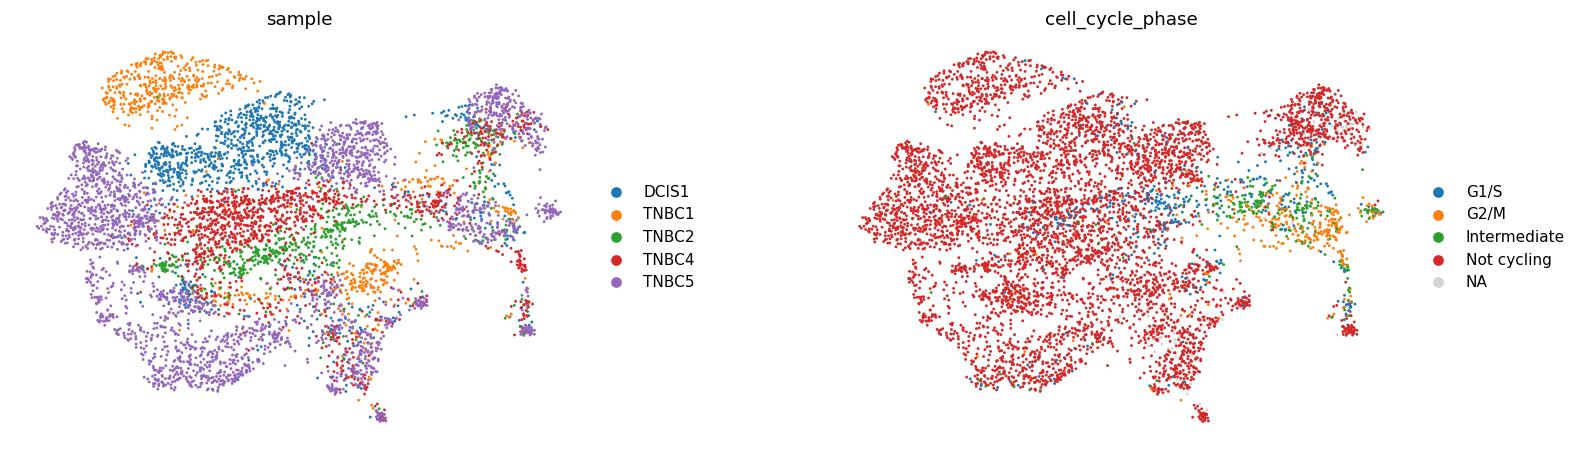

In [10]:
sc.pl.umap(adata, color=['sample', 'cell_cycle_phase'], size=14, frameon=False, wspace=.3)

In [11]:
# quantify the θ=10 embedding: per-patient self-neighbour enrichment, and that the cross-patient
# mixing that DOES occur is enriched for cycling cells (proliferation, not a shared cell state).
isl = self_enrich(adata.obsm['X_pca_harmony'][:, :NPCS], pat)
print('per-patient self-neighbour enrichment at theta=10 (self/global; >2.5x = a local island):')
for p, e in isl.items():
    print(f'  {p}: {e:.1f}x  {"SEGREGATED" if e > 2.5 else "partly mixed"}')
sf10 = same_frac(adata.obsm['X_pca_harmony'][:, :NPCS], samp)
cyc = adata.obs['cell_cycle_phase'].astype(str).values != 'Not cycling'
print(f'\ncross-patient mixing is proliferation-driven: cycling fraction in MIXED neighbourhoods '
      f'(same-kNN<0.4) = {cyc[sf10<0.4].mean():.1%} vs {cyc[sf10>0.7].mean():.1%} in PRIVATE (>70% own-sample) ones')

per-patient self-neighbour enrichment at theta=10 (self/global; >2.5x = a local island):
  DCIS1: 3.5x  SEGREGATED
  TNBC1: 5.0x  SEGREGATED
  TNBC2: 5.1x  SEGREGATED
  TNBC4: 3.5x  SEGREGATED
  TNBC5: 2.3x  partly mixed

cross-patient mixing is proliferation-driven: cycling fraction in MIXED neighbourhoods (same-kNN<0.4) = 28.3% vs 12.8% in PRIVATE (>70% own-sample) ones


### Robustness — is the archipelago a PC-count artifact? (Chen 2020)
Too few PCs can manufacture a false patient-segregated read. Re-check per-patient enrichment at
n_pcs = 20/30/40 (θ=10 fixed).

In [12]:
print('n_pcs robustness (theta=10) - per-patient self/global enrichment:')
for NP in [20, 30, 40]:
    e = self_enrich(adata.obsm['X_pca_harmony'][:, :NP], pat)
    print(f'  n_pcs={NP}: worst={max(e.values())}x  {"SEGREGATED (NO-GO holds)" if max(e.values()) > 2.5 else "mixed"}')
print('-> the archipelago is PC-count-invariant (NOT the Chen under-powering mode).')

n_pcs robustness (theta=10) - per-patient self/global enrichment:
  n_pcs=20: worst=5.2x  SEGREGATED (NO-GO holds)
  n_pcs=30: worst=5.1x  SEGREGATED (NO-GO holds)
  n_pcs=40: worst=5.2x  SEGREGATED (NO-GO holds)
-> the archipelago is PC-count-invariant (NOT the Chen under-powering mode).


### Identity or biology? Score the embryonic modules
If every patient carries the **same** modules but sits apart, the geometry is inter-patient
CNV/clonal heterogeneity — not the shared, sample-integrated cell-state continuum the protocol
requires. (Module scores also let Gate-2 branching be pre-excluded: no Gast/pSom hub.)

In [13]:
feat = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data, 'features', 'biomart', '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab2 in [('GSE162534', 'Gast'), ('GSE229103', 'pSom'), ('rRNAModifications', 'Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab2, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab2}: {g.size}/{feat[src].nunique()} genes present')
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].astype(str).isin(['G1/S', 'G2/M', 'Intermediate'])
print('\nper patient: (n, cycling frac, module means) + within-patient module correlations:')
for p in sorted(adata.obs['sample'].unique()):
    o = adata.obs[adata.obs['sample'] == p]
    gpc = np.corrcoef(o.Gast, o.pSom)[0, 1]; cp = np.corrcoef(o.Crest, o.pSom)[0, 1]
    print(f'  {p} (n={len(o):5d}): cycling={o["cycling"].mean():.2f} '
          f'Gast={o.Gast.mean():+.3f} pSom={o.pSom.mean():+.3f} Crest={o.Crest.mean():+.3f} '
          f'| within-pt Gast~pSom={gpc:+.2f} Crest~pSom={cp:+.2f}')
print('global module means:', adata.obs[['Gast', 'pSom', 'Crest']].mean().round(3).to_dict())
print('-> every tumour carries the same low-amplitude embryonic modules; geography is identity, not a shared axis.')

Gast: 79/81 genes present
pSom: 94/98 genes present
Crest: 103/104 genes present

per patient: (n, cycling frac, module means) + within-patient module correlations:
  DCIS1 (n= 1101): cycling=0.09 Gast=-0.015 pSom=+0.030 Crest=-0.035 | within-pt Gast~pSom=-0.08 Crest~pSom=-0.55
  TNBC1 (n=  796): cycling=0.18 Gast=-0.055 pSom=+0.062 Crest=-0.085 | within-pt Gast~pSom=-0.04 Crest~pSom=-0.57
  TNBC2 (n=  618): cycling=0.29 Gast=-0.021 pSom=-0.042 Crest=-0.009 | within-pt Gast~pSom=-0.14 Crest~pSom=-0.64
  TNBC4 (n= 1249): cycling=0.23 Gast=-0.030 pSom=+0.028 Crest=-0.022 | within-pt Gast~pSom=-0.13 Crest~pSom=-0.57
  TNBC5 (n= 2647): cycling=0.11 Gast=-0.017 pSom=+0.005 Crest=-0.050 | within-pt Gast~pSom=-0.29 Crest~pSom=-0.37
global module means: {'Gast': -0.024, 'pSom': 0.016, 'Crest': -0.042}
-> every tumour carries the same low-amplitude embryonic modules; geography is identity, not a shared axis.


## Gate 1 verdict — **NO-GO**

* The un-integrated malignant compartment is a **per-patient archipelago** (θ=0 patient silhouette
  **≈ +0.5**; **~78 % of all variance is between-patient**; the dense kNN graph is nonetheless one
  connected component — the first sign the connectivity scalar is uninformative here).
* Integration never achieves genuine per-neighbourhood mixing: **iLISI peaks at ≈1.6 of a 3.8
  ceiling (~42 %)** at θ=10, **same-sample kNN stays ~2.9× the mixed baseline**, **~67 % of cells
  keep own-sample-private neighbourhoods**, and the **worst patient self-enrichment is ~5×**;
  stronger θ does not help. Harmony drives the *global* patient silhouette/R² to ~0 and leaves one
  connected component + a round cloud — precisely the connectivity/global-scalar trap the Bischoff
  and Kürten audits flag; the embedding and per-neighbourhood metrics tell the true story.
* The archipelago is **PC-count-invariant** (holds at n_pcs 20/30/40) — not the Chen under-powering
  artifact. The only genuinely cross-patient axis is **proliferation** (cycling enriched in the mixed
  neighbourhoods) — the Kürten fork-2 confound, not a shared developmental state.
* Every tumour expresses the **same** low-amplitude embryonic modules while sitting apart: the
  geography is **inter-patient CNV/clonal heterogeneity**, not a shared, sample-integrated continuum.

Per the protocol — *"NO-GO if it clusters by sample or breaks into disconnected islands — don't force
a trajectory."* This **corrects the prior attempts**, which forced a `curve` across the θ=10
over-integrated blob and called GO. → **Gate 1 = NO-GO.** Downstream trajectory/signature notebooks
are NOT produced; the unconditional EMT-TF expression step follows as **02_expression**.

In [14]:
print('GATE 1: NO-GO (breast malignant structure clusters by patient; not a continuous integrated manifold)')

GATE 1: NO-GO (breast malignant structure clusters by patient; not a continuous integrated manifold)


In [15]:
# tidy obs dtypes -> save processed manifold (best integration attempt; read by 02_expression).
for col in adata.obs.columns:
    ssx = adata.obs[col]
    if ssx.dtype == object:
        conv = pd.to_numeric(ssx, errors='coerce')
        adata.obs[col] = conv if (ssx.notna().sum() and conv.notna().sum() >= 0.9*ssx.notna().sum()) else ssx.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (6411, 18061)


### Deliverable — `samples.pdf`
The Gate-1 evidence as a single sample-coloured manifold UMAP (reference style: one panel + external
legend). The per-patient local self-clustering, visible even after best-effort integration, IS the NO-GO.

saved samples.pdf | cells: 6411


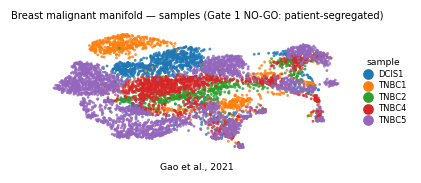

In [16]:
xy = adata.obsm['X_umap']
xlo, xhi = np.percentile(xy[:, 0], [0.3, 99.7]); ylo, yhi = np.percentile(xy[:, 1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(adata, color='sample', size=14, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.3, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Breast malignant manifold — samples (Gate 1 NO-GO: patient-segregated)', size=6.5)
ax.text(.5, -.12, 'Gao et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', adata.shape[0])